# soil_moisture_forecasting

# An Edge-Intelligence and Uncertainty-Aware Framework for IoT-Driven Precision Irrigation by Integrating Real-Time Soil Dynamics with Predictive Machine Learning

In [13]:
%pip install streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 5.3 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 797.2/797.2 kB 4.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 36.4/36.4 MB 4.5 MB/s  0:00:07m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 5.7 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10/10 [streamlit]10 [streamlit]

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [1]:

# ============================================================
# RESEARCH PROJECT: UNCERTAINTY-AWARE SMART IRRIGATION
# Soil Moisture Forecasting Using Machine Learning
# Dataset: sm_Uttarakhand_2020.csv
# ============================================================


from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import ( RandomForestRegressor,GradientBoostingRegressor)

from sklearn.metrics import (mean_absolute_error,mean_squared_error,  r2_score)

from xgboost import (XGBRegressor)


# ============================================================
# 1. CONFIGURATION
# ============================================================

BASE_DIR = Path.cwd()

# CSV file
DATA_PATH = BASE_DIR / "sm_Uttarakhand_2020.csv"

RESULTS_DIR = BASE_DIR / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Exact column names from  dataset
DATE_COL = "Date"
DISTRICT_COL = "DistrictName"
TARGET = "Aggregate Soilmoisture Percentage (at 15cm)"

print("Working directory:", BASE_DIR)
print("Dataset path:", DATA_PATH)
print("Dataset exists:", DATA_PATH.exists())

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"\nCSV file not found: {DATA_PATH}\n"
        "Place sm_Uttarakhand_2020.csv in the notebook folder, "
        "or update DATA_PATH to the correct location."
    )




Working directory: /Users/anish/Desktop/python /project
Dataset path: /Users/anish/Desktop/python /project/sm_Uttarakhand_2020.csv
Dataset exists: True


In [2]:
# ============================================================
# 2. LOAD AND INSPECT DATA
# ============================================================

df = pd.read_csv(DATA_PATH)

print("\nOriginal dataset shape:", df.shape)
print("\nAvailable columns:")
print(df.columns.tolist())

required = [DATE_COL, DISTRICT_COL, TARGET]
missing_columns = [c for c in required if c not in df.columns]

if missing_columns:
    raise ValueError(
        f"Missing columns: {missing_columns}\n"
        f"Available columns: {df.columns.tolist()}\n"
        "Check spelling, capitalization, and spaces in the CSV headers."
    )

# Convert columns into appropriate data types
df[DATE_COL] = pd.to_datetime(df[DATE_COL], errors="coerce")
df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")

# Remove records missing essential values
df = df.dropna(subset=[DATE_COL, DISTRICT_COL, TARGET]).copy()

df[DISTRICT_COL] = df[DISTRICT_COL].astype(str).str.strip()

# Remove empty district names
df = df[df[DISTRICT_COL] != ""].copy()

# Sort observations chronologically within each district
df = df.sort_values([DISTRICT_COL, DATE_COL]).reset_index(drop=True)

if df.empty:
    raise ValueError(
        "No valid rows remain after cleaning. "
        "Check your date and soil-moisture columns."
    )

print("\n========== CLEANED DATASET ==========")
print("Rows:", len(df))
print("Columns:", df.columns.tolist())
print("Date range:", df[DATE_COL].min(), "to", df[DATE_COL].max())
print("Number of districts:", df[DISTRICT_COL].nunique())
print("\nMissing values:")
print(df.isnull().sum())
print("\nFirst five records:")
print(df.head())

df.to_csv(RESULTS_DIR / "cleaned_data.csv", index=False)


Original dataset shape: (3224, 7)

Available columns:
['Date', 'State Name', 'DistrictName', 'Average Soilmoisture Level (at 15cm)', 'Average SoilMoisture Volume (at 15cm)', 'Aggregate Soilmoisture Percentage (at 15cm)', 'Volume Soilmoisture percentage (at 15cm)']

========== CLEANED DATASET ==========
Rows: 3224
Columns: ['Date', 'State Name', 'DistrictName', 'Average Soilmoisture Level (at 15cm)', 'Average SoilMoisture Volume (at 15cm)', 'Aggregate Soilmoisture Percentage (at 15cm)', 'Volume Soilmoisture percentage (at 15cm)']
Date range: 2020-01-01 00:00:00 to 2020-09-23 00:00:00
Number of districts: 13

Missing values:
Date                                           0
State Name                                     0
DistrictName                                   0
Average Soilmoisture Level (at 15cm)           0
Average SoilMoisture Volume (at 15cm)          0
Aggregate Soilmoisture Percentage (at 15cm)    0
Volume Soilmoisture percentage (at 15cm)       0
dtype: int64

First five 

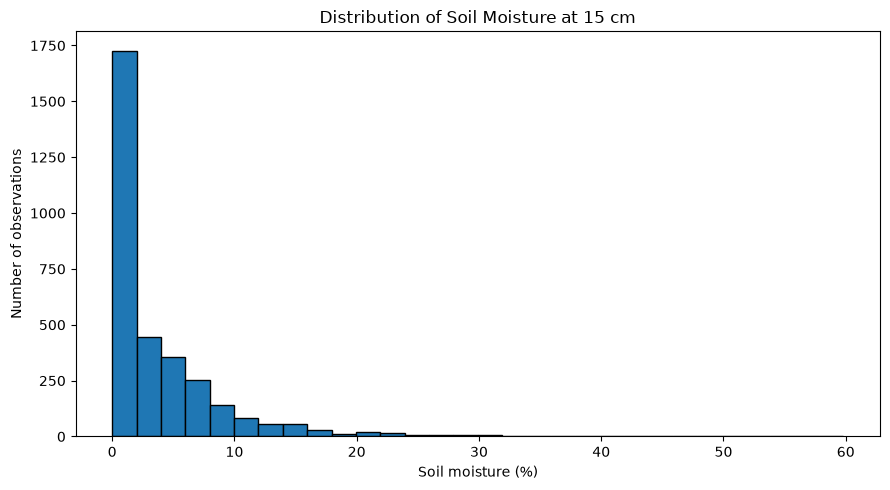

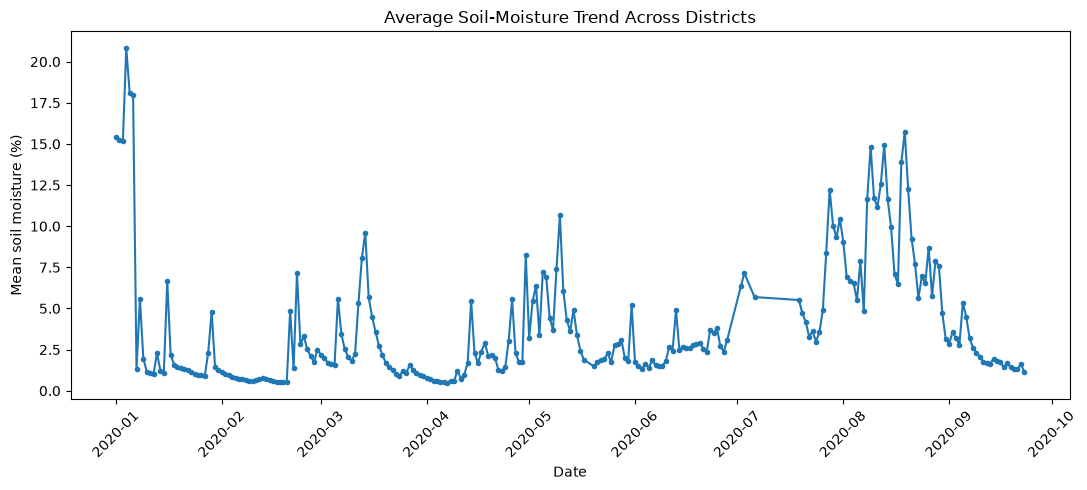

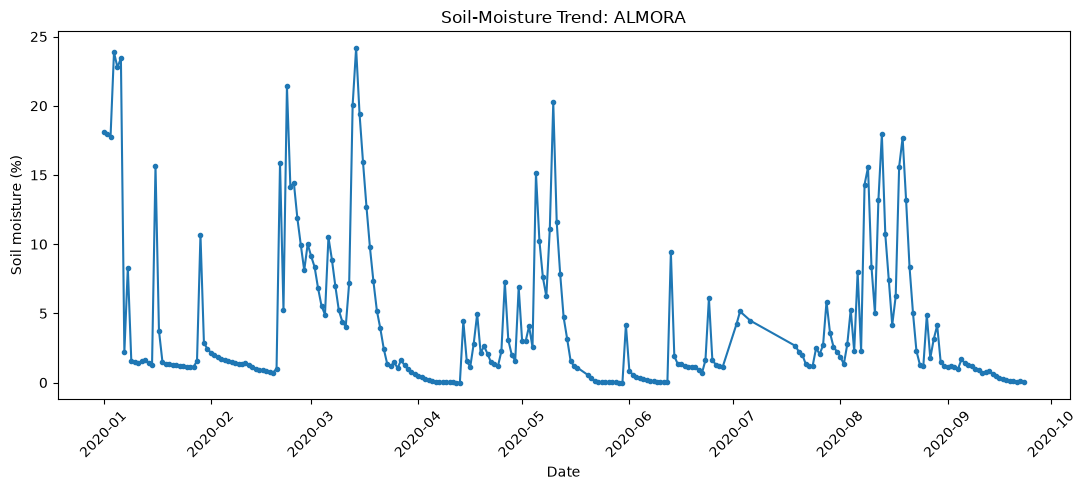

District selected for visualization: ALMORA


In [3]:
# ============================================================
# 3. EXPLORATORY DATA ANALYSIS (EDA)
# ============================================================

# Graph 1: Distribution of soil moisture
plt.figure(figsize=(9, 5))
plt.hist(df[TARGET], bins=30, edgecolor="black")
plt.xlabel("Soil moisture (%)")
plt.ylabel("Number of observations")
plt.title("Distribution of Soil Moisture at 15 cm")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "moisture_distribution.png", dpi=150)
plt.show()

# Graph 2: Average soil moisture over time
daily_mean = (
    df.groupby(DATE_COL)[TARGET]
      .mean()
      .sort_index()
)

plt.figure(figsize=(11, 5))
plt.plot(daily_mean.index, daily_mean.values, marker=".")
plt.xlabel("Date")
plt.ylabel("Mean soil moisture (%)")
plt.title("Average Soil-Moisture Trend Across Districts")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "overall_moisture_trend.png", dpi=150)
plt.show()

# Graph 3: Trend for the district with the most observations
district = df[DISTRICT_COL].value_counts().idxmax()

district_df = (
    df[df[DISTRICT_COL] == district]
    .sort_values(DATE_COL)
)

plt.figure(figsize=(11, 5))
plt.plot(
    district_df[DATE_COL],
    district_df[TARGET],
    marker="."
)
plt.xlabel("Date")
plt.ylabel("Soil moisture (%)")
plt.title(f"Soil-Moisture Trend: {district}")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "district_moisture_trend.png", dpi=150)
plt.show()

print("District selected for visualization:", district)


In [4]:
# ============================================================
# 4. CREATE TIME-SERIES FEATURES
# ============================================================

# Predict the next recorded observation within each district.
# It is not necessarily the next day.

df["target_next"] = df.groupby(DISTRICT_COL)[TARGET].shift(-1)

df["target_date"] = df.groupby(DISTRICT_COL)[DATE_COL].shift(-1)

# Historical soil-moisture features
df["lag_1"] = df.groupby(DISTRICT_COL)[TARGET].shift(1)
df["lag_2"] = df.groupby(DISTRICT_COL)[TARGET].shift(2)

# Mean of the three previous observations, excluding current observation
df["previous_mean_3"] = (
    df.groupby(DISTRICT_COL)[TARGET]
      .transform(lambda s: s.shift(1).rolling(window=3).mean())
)

# Month of the current observation
df["month"] = df[DATE_COL].dt.month

# Remove rows without sufficient historical data or a future target
df = df.dropna(
    subset=[
        "target_next",
        "target_date",
        "lag_1",
        "lag_2",
        "previous_mean_3"
    ]
).copy()

if df.empty:
    raise ValueError(
        "Insufficient observations to create lag features. "
        "Each district needs several valid observations."
    )

df = df.reset_index(drop=True)

print("\nRows available for modeling:", len(df))
print("Distinct target dates:", df["target_date"].nunique())

if df["target_date"].nunique() < 3:
    raise ValueError(
        "Too few distinct target dates for a chronological train/test split."
    )


Rows available for modeling: 3172
Distinct target dates: 244


In [5]:
 #============================================================
# 5. PREPARE FEATURES AND CHRONOLOGICAL SPLIT
# ============================================================

numeric_features = [
    TARGET,
    "lag_1",
    "lag_2",
    "previous_mean_3",
    "month"
]

# One-hot encode district names
district_dummies = pd.get_dummies(
    df[DISTRICT_COL],
    prefix="district",
    dtype=int
)

X = pd.concat(
    [
        df[numeric_features].reset_index(drop=True),
        district_dummies.reset_index(drop=True)
    ],
    axis=1
)

y = df["target_next"].reset_index(drop=True)

# Split based on time, not random sampling
unique_target_dates = np.array(
    sorted(df["target_date"].unique())
)

split_index = int(len(unique_target_dates) * 0.80)
split_index = min(
    max(split_index, 1),
    len(unique_target_dates) - 1
)

cutoff_date = unique_target_dates[split_index]

# Training targets occur before cutoff; test targets occur on/after cutoff
train_mask = (
    df["target_date"].to_numpy() < cutoff_date
)

test_mask = ~train_mask

X_train = X.loc[train_mask].copy()
X_test = X.loc[test_mask].copy()

y_train = y.loc[train_mask].copy()
y_test = y.loc[test_mask].copy()

print("\n========== TRAIN/TEST SPLIT ==========")
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Test period starts:", cutoff_date)

if len(X_train) < 10 or len(X_test) < 2:
    raise ValueError(
        "Too few training or test records. "
        "Inspect your dataset and date distribution."
    )



========== TRAIN/TEST SPLIT ==========
Training rows: 2535
Testing rows: 637
Test period starts: 2020-08-06 00:00:00


In [6]:
# ============================================================
# 6. BASELINE MODEL
# ============================================================

# Simple baseline: next observation equals the current observation
baseline_predictions = X_test[TARGET].to_numpy()

# ============================================================
# 7. RANDOM FOREST REGRESSION
# ============================================================

rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=10,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)


xgb_model = XGBRegressor(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)
xgb_model.fit(X_train, y_train)
xgb_predictions = xgb_model.predict(X_test)



In [7]:
# ============================================================
# 8. EVALUATE MODELS
# ============================================================

def evaluate_model(name, actual, predicted):
    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    r2 = (
        r2_score(actual, predicted)
        if len(actual) >= 2
        else float("nan")
    )

    print(f"\n{name}")
    print(f"MAE  : {mae:.4f}")
    print(f"RMSE : {rmse:.4f}")
    print(f"R²   : {r2:.4f}")

    return {
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }

metrics = []

metrics.append(
    evaluate_model(
        "Persistence Baseline",
        y_test,
        baseline_predictions
    )
)

metrics.append(
    evaluate_model(
        "Random Forest",
        y_test,
        rf_predictions
    )
)

metrics.append(
    evaluate_model(
        "XGBoost",
        y_test,
        xgb_predictions
    )
)


Persistence Baseline
MAE  : 1.8759
RMSE : 3.3077
R²   : 0.7332

Random Forest
MAE  : 2.1270
RMSE : 3.4280
R²   : 0.7134

XGBoost
MAE  : 2.2557
RMSE : 3.6833
R²   : 0.6691


In [8]:

# ============================================================
# 9. UNCERTAINTY ESTIMATION
# ============================================================

# Estimate the 10th and 90th conditional quantiles.
# Together they form an estimated 80% prediction interval.
# They are not guaranteed confidence bounds.

lower_model = GradientBoostingRegressor(
    loss="quantile",
    alpha=0.10,
    n_estimators=100,
    max_depth=2,
    random_state=42
)

upper_model = GradientBoostingRegressor(
    loss="quantile",
    alpha=0.90,
    n_estimators=100,
    max_depth=2,
    random_state=42
)

lower_model.fit(X_train, y_train)
upper_model.fit(X_train, y_train)

lower_predictions = lower_model.predict(X_test)
upper_predictions = upper_model.predict(X_test)

# Ensure lower bound does not exceed upper bound
lower_bound = np.minimum(
    lower_predictions,
    upper_predictions
)

upper_bound = np.maximum(
    lower_predictions,
    upper_predictions
)

actual = y_test.to_numpy()

coverage = np.mean(
    (actual >= lower_bound) &
    (actual <= upper_bound)
)

mean_width = np.mean(upper_bound - lower_bound)

print("\n========== UNCERTAINTY RESULTS ==========")
print("Nominal prediction interval: 80%")
print(f"Observed test coverage: {coverage:.4f}")
print(f"Mean interval width: {mean_width:.4f}")

xgb_lower = XGBRegressor(
    objective="reg:quantileerror", quantile_alpha=0.10,
    n_estimators=300, max_depth=3, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1
)
xgb_upper = XGBRegressor(
    objective="reg:quantileerror", quantile_alpha=0.90,
    n_estimators=300, max_depth=3, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1
)
xgb_lower.fit(X_train, y_train)
xgb_upper.fit(X_train, y_train)

xgb_lo_raw = xgb_lower.predict(X_test)
xgb_hi_raw = xgb_upper.predict(X_test)
xgb_lower_bound = np.minimum(xgb_lo_raw, xgb_hi_raw)
xgb_upper_bound = np.maximum(xgb_lo_raw, xgb_hi_raw)

xgb_coverage = np.mean((actual >= xgb_lower_bound) & (actual <= xgb_upper_bound))
xgb_width = np.mean(xgb_upper_bound - xgb_lower_bound)

print("\nXGBoost quantile interval (nominal 80%)")
print(f"Observed test coverage: {xgb_coverage:.4f}")
print(f"Mean interval width: {xgb_width:.4f}")


========== UNCERTAINTY RESULTS ==========
Nominal prediction interval: 80%
Observed test coverage: 0.7771
Mean interval width: 7.0553

XGBoost quantile interval (nominal 80%)
Observed test coverage: 0.7786
Mean interval width: 5.5782


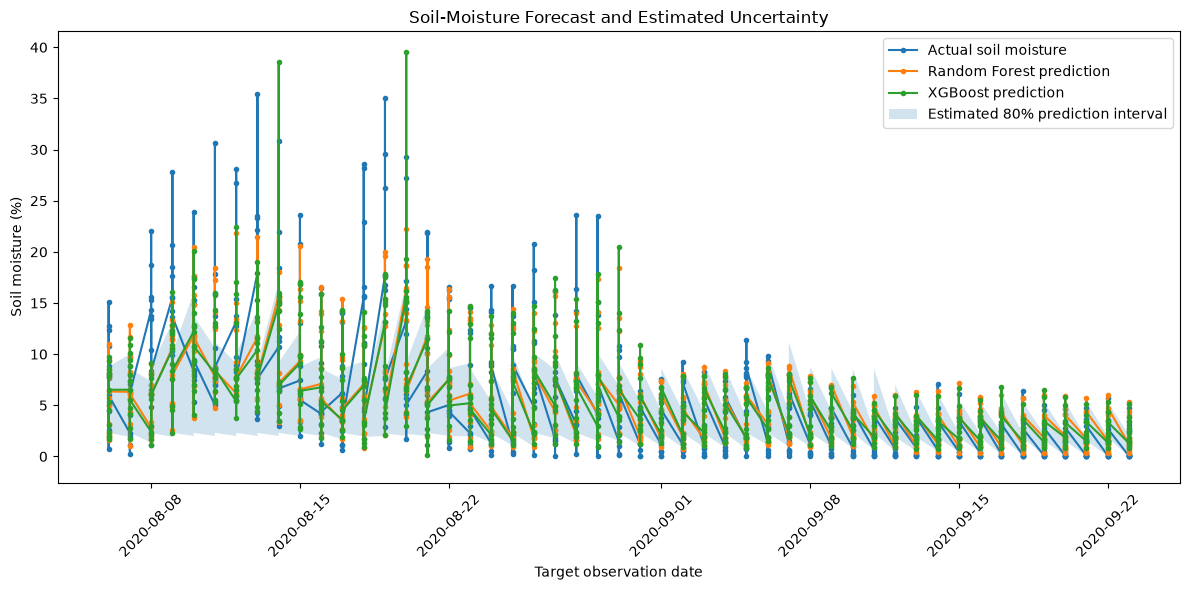

In [9]:


# ============================================================
# 10. SAVE AND VISUALIZE PREDICTIONS
# ============================================================

test_results = pd.DataFrame({
    "Date": df.loc[test_mask, "target_date"].to_numpy(),
    "District": df.loc[test_mask, DISTRICT_COL].to_numpy(),
    "Actual": y_test.to_numpy(),
    "Prediction": rf_predictions,
    "XGB_Prediction": xgb_predictions,
    "Lower": lower_bound,
    "Upper": upper_bound
})

test_results = test_results.sort_values(
    ["Date", "District"]
).reset_index(drop=True)

plt.figure(figsize=(12, 6))

plt.plot(
    test_results["Date"],
    test_results["Actual"],
    label="Actual soil moisture",
    marker="."
)

plt.plot(
    test_results["Date"],
    test_results["Prediction"],
    label="Random Forest prediction",
    marker="."
)
plt.plot(
    test_results["Date"],
    test_results["XGB_Prediction"],
    label="XGBoost prediction",
    marker="."
)

plt.fill_between(
    test_results["Date"],
    test_results["Lower"],
    test_results["Upper"],
    alpha=0.2,
    label="Estimated 80% prediction interval"
)

plt.xlabel("Target observation date")
plt.ylabel("Soil moisture (%)")
plt.title("Soil-Moisture Forecast and Estimated Uncertainty")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "forecast_uncertainty.png", dpi=150)
plt.show()



========== TOP 10 FEATURES ==========
                                    Feature  Importance
Aggregate Soilmoisture Percentage (at 15cm)    0.756968
                                      lag_1    0.083123
                            previous_mean_3    0.061718
                                      lag_2    0.050566
                                      month    0.021891
                         district_CHAMPAWAT    0.005243
                           district_HARDWAR    0.004879
                          district_NAINITAL    0.003896
                 district_UDHAM SINGH NAGAR    0.003027
                            district_ALMORA    0.002721


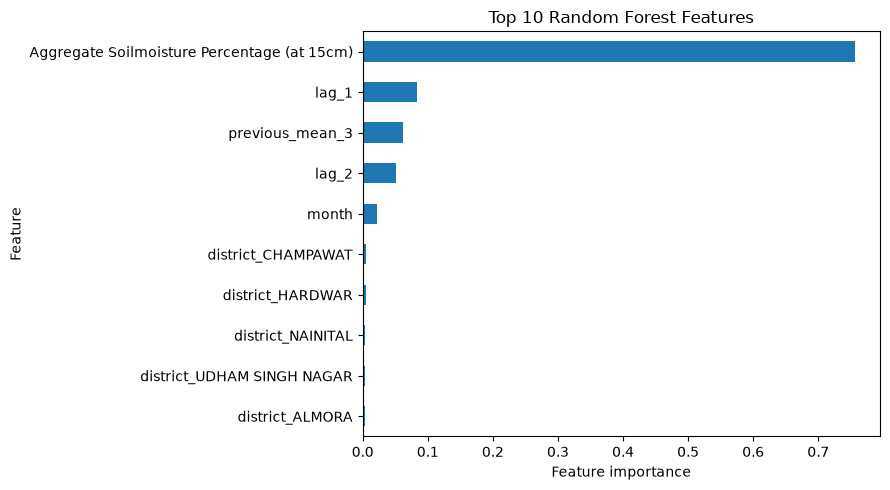


========== XGBOOST TOP 10 FEATURES ==========
                                    Feature  Importance
Aggregate Soilmoisture Percentage (at 15cm)    0.295206
                 district_UDHAM SINGH NAGAR    0.111268
                                      lag_1    0.097902
                            previous_mean_3    0.066710
                          district_NAINITAL    0.063238
                           district_HARDWAR    0.054597
                                      lag_2    0.042562
                         district_CHAMPAWAT    0.039357
                                      month    0.038822
                       district_PITHORAGARH    0.036080


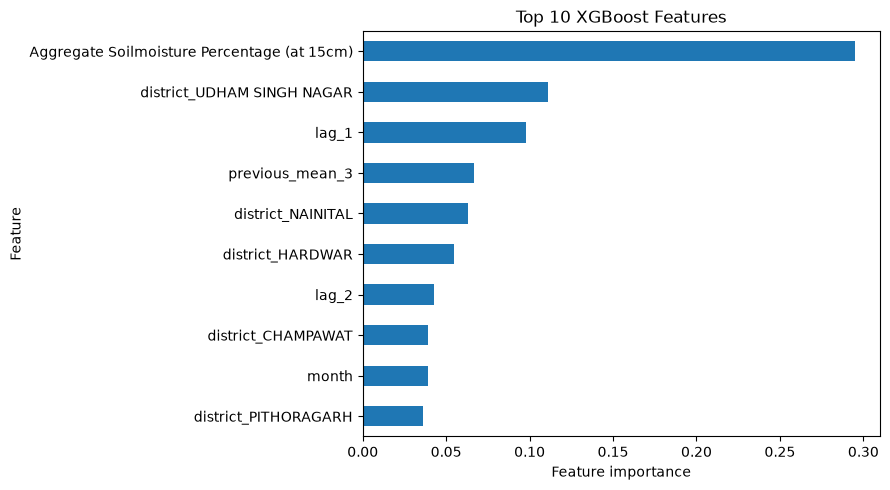


========== IRRIGATION DECISION DEMO ==========
Illustrative threshold: 0.33
      Date          District  Actual  Prediction         Lower    Upper                                  Decision
2020-09-23         CHAMPAWAT    0.02    1.396573  9.175653e-01 8.950740  WAIT: moisture predicted above threshold
2020-09-23          DEHRADUN    0.00    0.302374  7.968420e-07 2.834025 UNCERTAIN: check sensor/data and reassess
2020-09-23           GARHWAL    0.18    1.024936  9.923256e-02 2.262065 UNCERTAIN: check sensor/data and reassess
2020-09-23           HARDWAR    0.13    1.709293  1.036656e-02 2.032463 UNCERTAIN: check sensor/data and reassess
2020-09-23          NAINITAL    0.01    0.574816 -8.302692e-02 2.834025 UNCERTAIN: check sensor/data and reassess
2020-09-23       PITHORAGARH    2.72    4.105512  1.563188e+00 6.723573  WAIT: moisture predicted above threshold
2020-09-23       RUDRAPRAYAG    1.04    1.908424  9.710434e-01 4.440912  WAIT: moisture predicted above threshold
2020-09-23 

In [10]:


# ============================================================
# 11. FEATURE IMPORTANCE
# ============================================================

importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

print("\n========== TOP 10 FEATURES ==========")
print(importance.head(10).to_string(index=False))

importance.head(10).sort_values("Importance").plot(
    x="Feature",
    y="Importance",
    kind="barh",
    legend=False,
    figsize=(9, 5)
)

plt.xlabel("Feature importance")
plt.title("Top 10 Random Forest Features")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "feature_importance.png", dpi=150)
plt.show()


# ---------- >>> NEW: XGBOOST FEATURE IMPORTANCE (paste from here) ----------

xgb_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": xgb_model.feature_importances_
}).sort_values("Importance", ascending=False)

print("\n========== XGBOOST TOP 10 FEATURES ==========")
print(xgb_importance.head(10).to_string(index=False))

xgb_importance.head(10).sort_values("Importance").plot(
    x="Feature",
    y="Importance",
    kind="barh",
    legend=False,
    figsize=(9, 5)
)

plt.xlabel("Feature importance")
plt.title("Top 10 XGBoost Features")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "xgb_feature_importance.png", dpi=150)
plt.show()

xgb_importance.to_csv(RESULTS_DIR / "xgb_feature_importance.csv", index=False)

# ============================================================
# 12. ILLUSTRATIVE IRRIGATION DECISION
# ============================================================

# Demonstration threshold only.
# This is NOT a validated wheat irrigation threshold.
# Actual thresholds must be supported by agronomic evidence,
# soil type, crop growth stage, and field sensor calibration.

demo_threshold = float(y_train.quantile(0.25))

def irrigation_decision(lower, upper, threshold):
    if upper < threshold:
        return "ALERT: verify need for irrigation"
    elif lower > threshold:
        return "WAIT: moisture predicted above threshold"
    else:
        return "UNCERTAIN: check sensor/data and reassess"

test_results["Decision"] = [
    irrigation_decision(lo, hi, demo_threshold)
    for lo, hi in zip(
        test_results["Lower"],
        test_results["Upper"]
    )
]

print("\n========== IRRIGATION DECISION DEMO ==========")
print("Illustrative threshold:", round(demo_threshold, 4))

print(
    test_results[
        [
            "Date",
            "District",
            "Actual",
            "Prediction",
            "Lower",
            "Upper",
            "Decision"
        ]
    ].tail(10).to_string(index=False)
)

In [ ]:
# ============================================================
# 13. SAVE RESULTS
# ============================================================

test_results.to_csv(
    RESULTS_DIR / "test_predictions_with_decisions.csv",
    index=False
)

metrics_df = pd.DataFrame(metrics)
metrics_df.to_csv(
    RESULTS_DIR / "model_metrics.csv",
    index=False
)

importance.to_csv(
    RESULTS_DIR / "feature_importance.csv",
    index=False
)



# XGBoost feature importance
xgb_importance.to_csv(
    RESULTS_DIR / "xgb_feature_importance.csv",
    index=False
)

# Uncertainty comparison: Gradient Boosting vs XGBoost quantile intervals
# (requires Step 4. If you skipped it, delete this block.)
uncertainty_summary = pd.DataFrame([
    {
        "Model": "Gradient Boosting Quantile",
        "Nominal_Interval": 0.80,
        "Observed_Coverage": coverage,
        "Mean_Width": mean_width
    },
    {
        "Model": "XGBoost Quantile",
        "Nominal_Interval": 0.80,
        "Observed_Coverage": xgb_coverage,
        "Mean_Width": xgb_width
    }
])
uncertainty_summary.to_csv(
    RESULTS_DIR / "uncertainty_comparison.csv",
    index=False
)

# Report the best model by lowest RMSE
best = metrics_df.loc[metrics_df["RMSE"].idxmin()]
print("\n========== MODEL COMPARISON ==========")
print(metrics_df.round(4).to_string(index=False))
print(f"\nBest model by RMSE: {best['Model']} (RMSE = {best['RMSE']:.4f})")

print("\n========== UNCERTAINTY COMPARISON ==========")
print(uncertainty_summary.round(4).to_string(index=False))



print("\n================================================")
print("EXPERIMENT COMPLETED")
print("Results saved in:", RESULTS_DIR.resolve())
print("Files created:")
print("- cleaned_data.csv")
print("- model_metrics.csv")
print("- test_predictions_with_decisions.csv")
print("- feature_importance.csv")
print("- xgb_feature_importance.csv")        
print("- uncertainty_comparison.csv")         
print("- moisture_distribution.png")
print("- overall_moisture_trend.png")
print("- district_moisture_trend.png")
print("- forecast_uncertainty.png")
print("- feature_importance.png")
print("- xgb_feature_importance.png")         
print("================================================")


========== MODEL COMPARISON ==========
               Model    MAE   RMSE     R2
Persistence Baseline 1.8759 3.3077 0.7332
       Random Forest 2.1270 3.4280 0.7134
             XGBoost 2.2557 3.6833 0.6691

Best model by RMSE: Persistence Baseline (RMSE = 3.3077)

========== UNCERTAINTY COMPARISON ==========
                     Model  Nominal_Interval  Observed_Coverage  Mean_Width
Gradient Boosting Quantile               0.8             0.7771      7.0553
          XGBoost Quantile               0.8             0.7786      5.5782

EXPERIMENT COMPLETED
Results saved in: /Users/anish/Desktop/python /project/results
Files created:
- cleaned_data.csv
- model_metrics.csv
- test_predictions_with_decisions.csv
- feature_importance.csv
- xgb_feature_importance.csv
- uncertainty_comparison.csv
- moisture_distribution.png
- overall_moisture_trend.png
- district_moisture_trend.png
- forecast_uncertainty.png
- feature_importance.png
- xgb_feature_importance.png
